# Discovering Wholesale Customer Segments

**Methodology:** KDD  
**Dataset:** UCI Wholesale Customers, mirrored/listed on Kaggle; 440 customers with annual spend in six product categories, plus Channel and Region. This is an exploratory segmentation exercise, not a validated customer taxonomy.

This Colab-compatible notebook contains the executed analysis and saved outputs. Re-run top to bottom in Colab to reproduce; reports reflect the saved local run.

## Project charter

A wholesale distributor wants an exploratory view of purchasing profiles to help account teams plan interviews and service experiments. Clusters are hypotheses, not customer facts or automated treatment rules.

**Analytical objective:** Find stable, interpretable spending profiles in six annual category-spend features. Compare candidate k values with silhouette score, inspect cluster sizes and original-unit profiles, and treat geographic/channel fields as descriptive context only.

**Proposed acceptance and constraints:** Explore profiles that are interpretable and repeatable under a fixed analysis design. Business utility is not established until account owners define a decision and review the profiles.

**Decision boundary:** no customer-treatment decision is supported until stakeholders establish utility and fairness; clustering is descriptive, not causal, and may not generalize.

**Dataset provenance:** [Kaggle listing](https://www.kaggle.com/binovi/wholesale-customers-data-set); reproducible canonical download: [UCI archive](https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip). Check the source license and terms before redistribution.

## Environment and reproducibility

The notebook installs common packages in Colab. The data are fetched from the public UCI archive. Fixed random seeds are used where sampling or initialization applies. A network connection is required for first execution.

In [1]:
# Colab-ready setup; rerun this cell if the runtime is reset.
%pip -q install pandas==3.1.0 numpy==2.5.4 scikit-learn==1.9.1 matplotlib==3.11.2 joblib==1.6.0
import warnings
import hashlib, sklearn
from datetime import datetime, timezone
warnings.filterwarnings("ignore")
from IPython.display import display
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error, r2_score, silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.model_selection import train_test_split
print("Environment ready", {"pandas":pd.__version__,"numpy":np.__version__,"scikit_learn":sklearn.__version__})


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: /private/tmp/crispdm-assignment-venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Environment ready {'pandas': '3.1.0', 'numpy': '2.5.4', 'scikit_learn': '1.9.1'}


## 1. Selection

**Purpose and tasks.** Select the relevant records, domain subset, and variables from the source; justify the six spend features and contextual metadata.

**Phase intent.** Explore profiles that are interpretable and repeatable under a fixed analysis design. Business utility is not established until account owners define a decision and review the profiles.

**Project-specific decision.** Explore profiles that are interpretable and repeatable under a fixed analysis design. Business utility is not established until account owners define a decision and review the profiles.

**Expected evidence.** Observed: all 440 rows and six nonnegative spend variables are retained; metadata is excluded from fit. The raw-spend k=2 candidate fails cohesion for its 36-member cluster, and no stakeholder utility gate is established.

**Independent critique and revision record.** GPT-5.6 review pass 1 challenged using Channel/Region as spend dimensions, scale-sensitive distance, and treating the silhouette maximum as a real customer taxonomy. Revisions restrict clustering to spend, compare four representations, report per-cluster cohesion, resampling stability, and seed sensitivity, and mark the artifact unapproved. GPT-5.6 review pass 2 identified a mismatch between one-start seed sensitivity and the saved n_init=20 estimator, missing resampling/profile checks for alternate representations, an imprecise ARI label, omitted Channel context, and placeholder limitations. Revisions test the saved configuration, resample and profile each representation, distinguish sampled-subset ARI from projected cluster sizes, report Channel proportions, and replace the limitations prompt with data-specific limits. GPT-5.6 pass 3 found that alternate cluster profiles were incomplete, the article needed an explicit sampled-row ARI definition, and a one-start comparison was unsupported. The final notebook now reports original-unit and category-share summaries plus Channel/Region context for every representation; the article states ARI scope precisely and the report compares only the saved 20-start configuration. Setup versions are pinned and source hashes are asserted.

## 2. Preprocessing

**Purpose and tasks.** Inspect, clean, and validate records; quantify missingness, duplicates, impossible values, and data limitations.

**Phase intent.** Inspect source, schema, missingness, distributions, quality, and assumptions before modeling.

**Project-specific decision.** UCI Wholesale Customers, mirrored/listed on Kaggle; 440 customers with annual spend in six product categories, plus Channel and Region. This is an exploratory segmentation exercise, not a validated customer taxonomy.

**Expected evidence.** Executed checks: 440×8; no nulls, invalid Channel/Region codes, nonfinite or negative spends, full-row duplicates, or duplicate spend vectors. A source_row_id is retained in the assignment file. The dataset has no time or account-level context.

**Independent critique and revision record.** GPT-5.6 review pass 1 challenged using Channel/Region as spend dimensions, scale-sensitive distance, and treating the silhouette maximum as a real customer taxonomy. Revisions restrict clustering to spend, compare four representations, report per-cluster cohesion, resampling stability, and seed sensitivity, and mark the artifact unapproved. GPT-5.6 review pass 2 identified a mismatch between one-start seed sensitivity and the saved n_init=20 estimator, missing resampling/profile checks for alternate representations, an imprecise ARI label, omitted Channel context, and placeholder limitations. Revisions test the saved configuration, resample and profile each representation, distinguish sampled-subset ARI from projected cluster sizes, report Channel proportions, and replace the limitations prompt with data-specific limits. GPT-5.6 pass 3 found that alternate cluster profiles were incomplete, the article needed an explicit sampled-row ARI definition, and a one-start comparison was unsupported. The final notebook now reports original-unit and category-share summaries plus Channel/Region context for every representation; the article states ARI scope precisely and the report compares only the saved 20-start configuration. Setup versions are pinned and source hashes are asserted.

In [2]:
import io, zipfile, urllib.request
url = "https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip"
with urllib.request.urlopen(url, timeout=60) as response:
    archive_bytes = response.read()
retrieved_utc = datetime.now(timezone.utc).isoformat()
archive_sha256 = hashlib.sha256(archive_bytes).hexdigest()
assert archive_sha256 == "647e6a61683ed23f48c7b04e1e2be78835eca8758b32267603fc42a1479dbfb8", "UCI source archive changed; review before relying on saved results"
archive = zipfile.ZipFile(io.BytesIO(archive_bytes))
print(archive.namelist())
csv_bytes = archive.read("Wholesale customers data.csv")
csv_sha256 = hashlib.sha256(csv_bytes).hexdigest()
assert csv_sha256 == "c3d018c643565b85cee733c4a2ac76dd76e080e857cb23f0ccfcc2e15a6c17ef", "UCI source data changed; review before relying on saved results"
df = pd.read_csv(io.BytesIO(csv_bytes))
print("retrieved_utc",retrieved_utc,"archive_sha256",archive_sha256,"csv_sha256",csv_sha256)
df.head()

['Wholesale customers data.csv']
retrieved_utc 2026-10-27T03:30:25.174000+00:00 archive_sha256 647e6a61683ed23f48c7b04e1e2be78835eca8758b32267603fc42a1479dbfb8 csv_sha256 c3d018c643565b85cee733c4a2ac76dd76e080e857cb23f0ccfcc2e15a6c17ef


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.rename("dtype").to_frame())
display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing"))
display(df.describe(include="all").T.head(25))
spend_cols = ["Fresh","Milk","Grocery","Frozen","Detergents_Paper","Delicassen"]
print("full-row duplicates",int(df.duplicated().sum()),"invalid Channel",int((~df.Channel.isin([1,2])).sum()),"invalid Region",int((~df.Region.isin([1,2,3])).sum()))
print("nonfinite spend cells",int((~np.isfinite(df[spend_cols])).sum().sum()),"negative spend cells",int(df[spend_cols].lt(0).sum().sum()))

Shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


,dtype
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


,missing
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


full-row duplicates 0 invalid Channel 0 invalid Region 0
nonfinite spend cells 0 negative spend cells 0


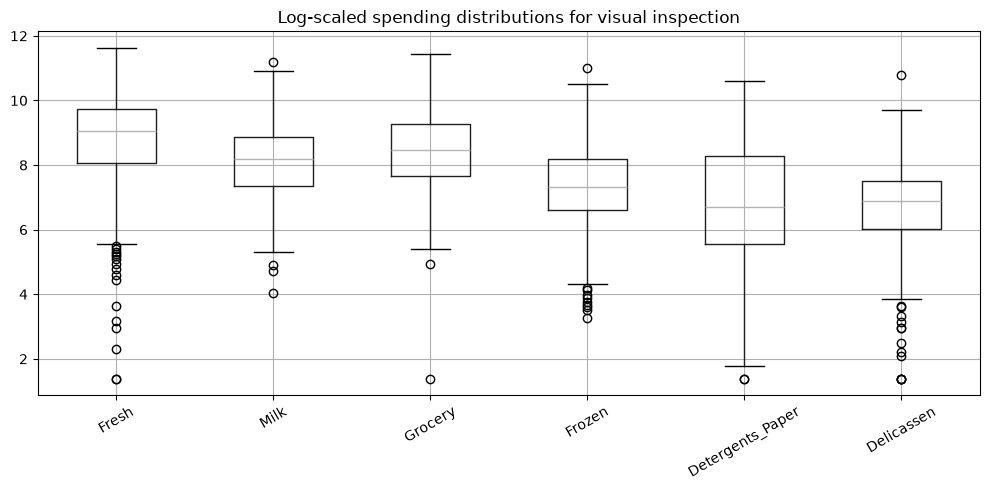

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
np.log1p(df[["Fresh","Milk","Grocery","Frozen","Detergents_Paper","Delicassen"]]).boxplot(ax=ax)
ax.set_title("Log-scaled spending distributions for visual inspection"); plt.xticks(rotation=30); plt.tight_layout()

**Observed data-quality record:** the executed output reports dimensions, nulls, full-row duplicates, allowed Channel/Region codes, finite/nonnegative spending checks, and repeated spending signatures. Repeated vectors are retained because the source does not identify whether they are distinct customers; treat identical profiles as indistinguishable for stability analysis.

## 3. Transformation

**Purpose and tasks.** Transform and standardize features for distance calculations; preserve original-unit features for interpretation; document reversibility.

**Phase intent.** Document the four spend representations, transformation choices, and how each scaler is refit inside every shared subsample; this is unsupervised mining, not a train/test prediction split.

**Project-specific decision.** UCI Wholesale Customers, mirrored/listed on Kaggle; 440 customers with annual spend in six product categories, plus Channel and Region. This is an exploratory segmentation exercise, not a validated customer taxonomy.

**Expected evidence.** Four representations are evaluated for k=2…7. The standardized category-share heuristic yields k=2 silhouette 0.377, balanced 196/244 sizes, and stronger per-cluster cohesion than the raw 36/404 partition. Every resample uses identical row indices across representations, with scaler refit inside the sample; all cluster summaries are profiled in original spend units and category shares.

**Independent critique and revision record.** GPT-5.6 review pass 1 challenged using Channel/Region as spend dimensions, scale-sensitive distance, and treating the silhouette maximum as a real customer taxonomy. Revisions restrict clustering to spend, compare four representations, report per-cluster cohesion, resampling stability, and seed sensitivity, and mark the artifact unapproved. GPT-5.6 review pass 2 identified a mismatch between one-start seed sensitivity and the saved n_init=20 estimator, missing resampling/profile checks for alternate representations, an imprecise ARI label, omitted Channel context, and placeholder limitations. Revisions test the saved configuration, resample and profile each representation, distinguish sampled-subset ARI from projected cluster sizes, report Channel proportions, and replace the limitations prompt with data-specific limits. GPT-5.6 pass 3 found that alternate cluster profiles were incomplete, the article needed an explicit sampled-row ARI definition, and a one-start comparison was unsupported. The final notebook now reports original-unit and category-share summaries plus Channel/Region context for every representation; the article states ARI scope precisely and the report compares only the saved 20-start configuration. Setup versions are pinned and source hashes are asserted.

In [5]:
spend = spend_cols
assert df[spend].ge(0).all().all()
assert df[spend].notna().all().all()
assert np.isfinite(df[spend].to_numpy()).all()
assert df["Channel"].isin([1,2]).all() and df["Region"].isin([1,2,3]).all()
metadata = df[["Channel","Region"]].copy()
X = df[spend].copy()
metadata["source_row_id"] = np.arange(len(df))
groups = pd.util.hash_pandas_object(X, index=False).astype(str)
group_channel_counts = pd.DataFrame({"group":groups,"channel":df["Channel"]}).groupby("group")["channel"].nunique()
print("Rows/features",X.shape,"duplicate spend vectors",int(X.duplicated().sum()),"unique signatures",groups.nunique(),"signatures occurring in multiple channels",int((group_channel_counts>1).sum()))
display(X.skew().rename("skewness").to_frame())
display(X.corr().round(2))
display(X.describe().T)

Rows/features (440, 6) duplicate spend vectors 0 unique signatures 440 signatures occurring in multiple channels 0


,skewness
Fresh,2.561323
Milk,4.053755
Grocery,3.587429
Frozen,5.907986
Detergents_Paper,3.631851
Delicassen,11.151586


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.00,0.10,-0.01,0.35,-0.10,0.24
Milk,0.10,1.00,0.73,0.12,0.66,0.41
Grocery,-0.01,0.73,1.00,-0.04,0.92,0.21
Frozen,0.35,0.12,-0.04,1.00,-0.13,0.39
Detergents_Paper,-0.10,0.66,0.92,-0.13,1.00,0.07
Delicassen,0.24,0.41,0.21,0.39,0.07,1.00


,count,mean,std,min,25%,50%,75%,max
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


## 4. Data Mining

**Purpose and tasks.** Apply clustering across candidate k values; use reproducible initialization and internal validity measures; record alternatives.

**Phase intent.** Compare candidate k=2…7 and four feature representations using fixed K-means settings and internal validity measures; there is no supervised prediction baseline in this unsupervised task.

**Project-specific decision.** UCI Wholesale Customers, mirrored/listed on Kaggle; 440 customers with annual spend in six product categories, plus Channel and Region. This is an exploratory segmentation exercise, not a validated customer taxonomy.

**Expected evidence.** The raw-spend provisional k=2 has aggregate silhouette 0.614 but the 36-record group mean silhouette is 0.020. In 100 shared subsamples with n_init=20 and random_state=42, k=2 is selected 100/100 times for raw, 100/100 log-standard, 87/100 log-robust, and 99/100 standardized category-share runs. Sampled-row ARI and Jaccard are reported separately from projected full-data cluster sizes; 25-seed sensitivity is evaluated separately with the saved configuration.

**Independent critique and revision record.** GPT-5.6 review pass 1 challenged using Channel/Region as spend dimensions, scale-sensitive distance, and treating the silhouette maximum as a real customer taxonomy. Revisions restrict clustering to spend, compare four representations, report per-cluster cohesion, resampling stability, and seed sensitivity, and mark the artifact unapproved. GPT-5.6 review pass 2 identified a mismatch between one-start seed sensitivity and the saved n_init=20 estimator, missing resampling/profile checks for alternate representations, an imprecise ARI label, omitted Channel context, and placeholder limitations. Revisions test the saved configuration, resample and profile each representation, distinguish sampled-subset ARI from projected cluster sizes, report Channel proportions, and replace the limitations prompt with data-specific limits. GPT-5.6 pass 3 found that alternate cluster profiles were incomplete, the article needed an explicit sampled-row ARI definition, and a one-start comparison was unsupported. The final notebook now reports original-unit and category-share summaries plus Channel/Region context for every representation; the article states ARI scope precisely and the report compares only the saved 20-start configuration. Setup versions are pinned and source hashes are asserted.

In [6]:
k_values = range(2, 8)
representations = {"raw_standard":(X,StandardScaler()),"log_standard":(np.log1p(X),StandardScaler()),"log_robust":(np.log1p(X),RobustScaler()),"category_share_standard":(X.div(X.sum(axis=1),axis=0),StandardScaler())}
rep_rows, rep_models = [], {}
for representation,(frame,transformer) in representations.items():
    Z_rep = transformer.fit_transform(frame)
    rep_models[representation] = {"transformer":transformer,"Z":Z_rep,"models":{}}
    for k in k_values:
        candidate = KMeans(n_clusters=k,n_init=20,random_state=42)
        lab = candidate.fit_predict(Z_rep)
        sil = silhouette_samples(Z_rep,lab)
        sizes = pd.Series(lab).value_counts()
        rep_rows.append({"representation":representation,"k":k,"silhouette":sil.mean(),"smallest_cluster":int(sizes.min()),"smallest_share":sizes.min()/len(X),"worst_cluster_mean_silhouette":min(sil[lab==c].mean() for c in np.unique(lab)),"negative_silhouette_share":(sil<0).mean()})
        rep_models[representation]["models"][k] = (candidate,lab)
representation_table = pd.DataFrame(rep_rows)
display(representation_table.sort_values(["representation","k"]))
raw_table = representation_table.query("representation == 'raw_standard'").sort_values("silhouette",ascending=False)
best_k = int(raw_table.iloc[0].k)
scaler = rep_models["raw_standard"]["transformer"]
Z = rep_models["raw_standard"]["Z"]
km, labels = rep_models["raw_standard"]["models"][best_k]
print("Provisional raw-spend candidate k (not a production selection):",best_k)
sil = silhouette_samples(Z,labels)
display(pd.DataFrame({"cluster":labels,"silhouette":sil}).groupby("cluster").silhouette.agg(["count","mean","median",lambda s:(s<0).mean()]).rename(columns={"<lambda_0>":"negative_share"}))
# Use the same 100 subsample row sets and fixed KMeans initialization seed for every representation.
subsample_rng = np.random.default_rng(20261026)
subsample_indices = [subsample_rng.choice(len(X),size=int(.8*len(X)),replace=False) for _ in range(100)]
representation_stability = {}
for representation,(frame,_) in representations.items():
    full_labels = rep_models[representation]["models"][2][1]
    reference_small = int(pd.Series(full_labels).value_counts().idxmin())
    ari_scores, jaccard_scores, small_cluster_sizes, selection_counts = [], [], [], []
    for idx in subsample_indices:
        frame_sub = frame.iloc[idx]
        sub_transformer = RobustScaler() if representation == "log_robust" else StandardScaler()
        Z_sub = sub_transformer.fit_transform(frame_sub)
        scores, fitted = {}, {}
        for k in k_values:
            model = KMeans(n_clusters=k,n_init=20,random_state=42)
            labels_sub = model.fit_predict(Z_sub)
            scores[k] = silhouette_score(Z_sub,labels_sub)
            fitted[k] = (model,labels_sub)
        selection_counts.append(max(scores,key=scores.get))
        sub_model, sub_labels = fitted[2]
        ari_scores.append(adjusted_rand_score(full_labels[idx],sub_labels))
        sub_small = int(pd.Series(sub_labels).value_counts().idxmin())
        reference_members = full_labels[idx] == reference_small
        subsample_members = sub_labels == sub_small
        jaccard_scores.append(float((reference_members & subsample_members).sum()/(reference_members | subsample_members).sum()))
        predicted_all = sub_model.predict(sub_transformer.transform(frame))
        small_cluster_sizes.append(int((predicted_all==sub_small).sum()))
    representation_stability[representation] = {"subsamples":100,"k2_selected":int(selection_counts.count(2)),"selection_frequency":pd.Series(selection_counts).value_counts(normalize=True).sort_index().to_dict(),"ARI_median_on_sampled_rows":float(np.median(ari_scores)),"ARI_min":float(np.min(ari_scores)),"ARI_max":float(np.max(ari_scores)),"small_cluster_Jaccard_median_on_sampled_rows":float(np.median(jaccard_scores)),"small_cluster_Jaccard_min":float(np.min(jaccard_scores)),"small_cluster_Jaccard_max":float(np.max(jaccard_scores)),"projected_small_cluster_size_min":int(np.min(small_cluster_sizes)),"projected_small_cluster_size_max":int(np.max(small_cluster_sizes))}
print("100 shared 80% subsamples; fixed n_init=20 and random_state=42; stability by representation:",representation_stability)
stability_summary = representation_stability["raw_standard"]
# Separate initialization sensitivity on the fixed full raw-spend data.
seed_ari = [adjusted_rand_score(labels,KMeans(n_clusters=best_k,n_init=20,random_state=s).fit_predict(Z)) for s in range(25)]
print("Raw-spend saved-config (n_init=20) seed sensitivity ARI median/min/max:",float(np.median(seed_ari)),float(np.min(seed_ari)),float(np.max(seed_ari)))

,representation,k,silhouette,smallest_cluster,smallest_share,worst_cluster_mean_silhouette,negative_silhouette_share
18,category_share_standard,2,0.377295,196,0.445455,0.307297,0.031818
19,category_share_standard,3,0.361770,71,0.161364,0.145338,0.045455
20,category_share_standard,4,0.344813,65,0.147727,0.131802,0.050000
21,category_share_standard,5,0.328787,43,0.097727,0.153146,0.045455
22,category_share_standard,6,0.298743,33,0.075000,0.139712,0.068182
23,category_share_standard,7,0.281175,24,0.054545,0.150166,0.038636
12,log_robust,2,0.252915,188,0.427273,0.211359,0.018182
13,log_robust,3,0.244659,80,0.181818,0.110640,0.050000
14,log_robust,4,0.201693,53,0.120455,0.070171,0.079545
15,log_robust,5,0.189820,37,0.084091,0.101512,0.075000


Provisional raw-spend candidate k (not a production selection): 2


,count,mean,median,negative_share
cluster,,,,
0,36,0.019562,-0.015618,0.527778
1,404,0.666636,0.711801,0.000000


100 shared 80% subsamples; fixed n_init=20 and random_state=42; stability by representation: {'raw_standard': {'subsamples': 100, 'k2_selected': 100, 'selection_frequency': {2: 1.0}, 'ARI_median_on_sampled_rows': 0.776452698809738, 'ARI_min': 0.39691043843200285, 'ARI_max': 1.0, 'small_cluster_Jaccard_median_on_sampled_rows': 0.7, 'small_cluster_Jaccard_min': 0.36619718309859156, 'small_cluster_Jaccard_max': 1.0, 'projected_small_cluster_size_min': 13, 'projected_small_cluster_size_max': 85}, 'log_standard': {'subsamples': 100, 'k2_selected': 100, 'selection_frequency': {2: 1.0}, 'ARI_median_on_sampled_rows': 0.9773206305991406, 'ARI_min': 0.7850366741769974, 'ARI_max': 1.0, 'small_cluster_Jaccard_median_on_sampled_rows': 0.9863479638430714, 'small_cluster_Jaccard_min': 0.8823529411764706, 'small_cluster_Jaccard_max': 1.0, 'projected_small_cluster_size_min': 181, 'projected_small_cluster_size_max': 211}, 'log_robust': {'subsamples': 100, 'k2_selected': 87, 'selection_frequency': {2: 0.

Raw-spend saved-config (n_init=20) seed sensitivity ARI median/min/max: 0.8987759591796203 0.8012722394273888 1.0


## 5. Interpretation/Evaluation

**Purpose and tasks.** Interpret clusters in original units and context; assess sizes and stability; reject unsupported causal or permanent segment claims; propose human validation.

**Phase intent.** Use metrics aligned to the task, inspect slices and failure cases, and distinguish measured evidence from proposed acceptance criteria.

**Project-specific decision.** Explore profiles that are interpretable and repeatable under a fixed analysis design. Business utility is not established until account owners define a decision and review the profiles.

**Expected evidence.** The raw cluster has weak cohesion and strong Channel association. The standardized category-share heuristic provides a more balanced geometry, but no profile has stakeholder validation or demonstrated decision utility; keep all labels exploratory and unapproved.

**Independent critique and revision record.** GPT-5.6 review pass 1 challenged using Channel/Region as spend dimensions, scale-sensitive distance, and treating the silhouette maximum as a real customer taxonomy. Revisions restrict clustering to spend, compare four representations, report per-cluster cohesion, resampling stability, and seed sensitivity, and mark the artifact unapproved. GPT-5.6 review pass 2 identified a mismatch between one-start seed sensitivity and the saved n_init=20 estimator, missing resampling/profile checks for alternate representations, an imprecise ARI label, omitted Channel context, and placeholder limitations. Revisions test the saved configuration, resample and profile each representation, distinguish sampled-subset ARI from projected cluster sizes, report Channel proportions, and replace the limitations prompt with data-specific limits. GPT-5.6 pass 3 found that alternate cluster profiles were incomplete, the article needed an explicit sampled-row ARI definition, and a one-start comparison was unsupported. The final notebook now reports original-unit and category-share summaries plus Channel/Region context for every representation; the article states ARI scope precisely and the report compares only the saved 20-start configuration. Setup versions are pinned and source hashes are asserted.

In [7]:
# Report cluster size, original-unit spend medians, category shares, cohesion, and held-out metadata for every k=2 representation.
representation_profiles=[]
for representation,(_,_) in representations.items():
    rep_labels=rep_models[representation]["models"][2][1]
    rep_sil=silhouette_samples(rep_models[representation]["Z"],rep_labels)
    totals=X.sum(axis=1)
    shares=X.div(totals,axis=0)
    for cluster_id in np.unique(rep_labels):
        mask=rep_labels==cluster_id
        row={"representation":representation,"cluster":int(cluster_id),"size":int(mask.sum()),"median_total_spend":float(totals[mask].median()),"mean_silhouette":float(rep_sil[mask].mean()),"median_silhouette":float(np.median(rep_sil[mask])),"negative_silhouette_share":float((rep_sil[mask]<0).mean()),"Channel_1_share":float((metadata.loc[mask,"Channel"]==1).mean()),"Channel_2_share":float((metadata.loc[mask,"Channel"]==2).mean()),"Region_1_share":float((metadata.loc[mask,"Region"]==1).mean()),"Region_2_share":float((metadata.loc[mask,"Region"]==2).mean()),"Region_3_share":float((metadata.loc[mask,"Region"]==3).mean())}
        row.update({"median_"+col:float(X.loc[mask,col].median()) for col in spend})
        row.update({"median_share_"+col:float(shares.loc[mask,col].median()) for col in spend})
        representation_profiles.append(row)
profiles_all=pd.DataFrame(representation_profiles).set_index(["representation","cluster"])
display(profiles_all.round(3))
raw_profile=profiles_all.loc["raw_standard"]
print("Raw-spend cluster cohesion and contextual profile:")
display(raw_profile[["size","mean_silhouette","median_silhouette","negative_silhouette_share","Channel_2_share","Region_3_share"]])
category_share_profile=profiles_all.loc["category_share_standard"]
print("Category-share representation produces a distinct, more balanced partition; this remains exploratory without stakeholder validation:")
display(category_share_profile[["size","mean_silhouette","negative_silhouette_share","Channel_2_share","Region_3_share"]])


size  median_total_spend  mean_silhouette  \
representation          cluster                                              
raw_standard            0          36             68707.0            0.020   
                        1         404             25832.5            0.667   
log_standard            0         252             19745.0            0.313   
                        1         188             35222.5            0.260   
log_robust              0         252             19857.5            0.284   
                        1         188             35172.0            0.211   
category_share_standard 0         196             30040.5            0.307   
                        1         244             25103.0            0.434   

                                 median_silhouette  negative_silhouette_share  \
representation          cluster                                                 
raw_standard            0                   -0.016                      0.528   
                        1                    0.712                      0.000   
log_standard            0                    0.353                      0.000   
                        1                    0.296                      0.043   
log_robust              0                    0.313                      0.000   
                        1                    0.234                      0.043   
category_share_standard 0                    0.354                      0.071   
                        1                    0.485                      0.000   

                                 Channel_1_share  Channel_2_share  \
representation          cluster                                     
raw_standard            0                  0.083            0.917   
                        1                  0.730            0.270   
log_standard            0                  0.968            0.032   
                        1                  0.287            0.713   
log_robust              0                  0.964            0.036   
                        1                  0.293            0.707   
category_share_standard 0                  0.393            0.607   
                        1                  0.906            0.094   

                                 Region_1_share  Region_2_share  \
representation          cluster                                   
raw_standard            0                 0.194           0.167   
                        1                 0.173           0.101   
log_standard            0                 0.190           0.111   
                        1                 0.154           0.101   
log_robust              0                 0.190           0.111   
                        1                 0.154           0.101   
category_share_standard 0                 0.158           0.102   
                        1                 0.189           0.111   

                                 Region_3_share  ...  median_Grocery  \
representation          cluster                  ...                   
raw_standard            0                 0.639  ...         26136.5   
                        1                 0.725  ...          4099.5   
log_standard            0                 0.698  ...          2406.0   
                        1                 0.745  ...         11527.0   
log_robust              0                 0.698  ...          2442.0   
                        1                 0.745  ...         11443.0   
category_share_standard 0                 0.740  ...         10582.0   
                        1                 0.701  ...          2610.0   

                                 median_Frozen  median_Detergents_Paper  \
representation          cluster                                           
raw_standard            0               1365.0                  12614.5   
                        1               1538.0                    708.0   
log_standard            0               2225.0            

Raw-spend cluster cohesion and contextual profile:


,size,mean_silhouette,median_silhouette,negative_silhouette_share,Channel_2_share,Region_3_share
cluster,,,,,,
0,36,0.019562,-0.015618,0.527778,0.916667,0.638889
1,404,0.666636,0.711801,0.000000,0.269802,0.725248


Category-share representation produces a distinct, more balanced partition; this remains exploratory without stakeholder validation:


,size,mean_silhouette,negative_silhouette_share,Channel_2_share,Region_3_share
cluster,,,,,
0,196,0.307297,0.071429,0.607143,0.739796
1,244,0.433523,0.000000,0.094262,0.700820


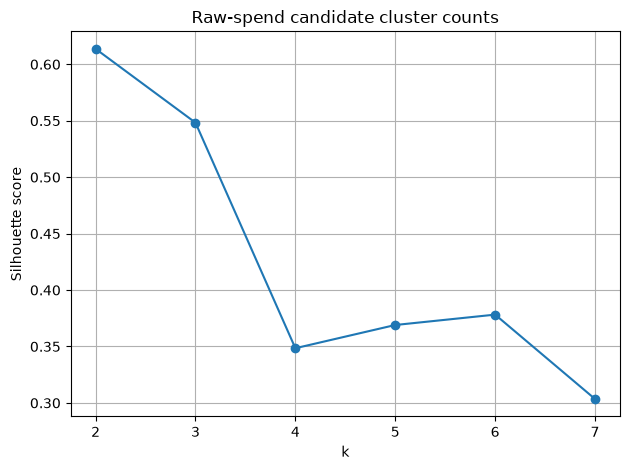

In [8]:
raw_table.sort_values("k").plot(x="k",y="silhouette",marker="o",legend=False,grid=True)
plt.ylabel("Silhouette score"); plt.title("Raw-spend candidate cluster counts"); plt.tight_layout()

**Evaluation record:** The saved outputs show the representation comparison, weak small-cluster cohesion, and resampling/seed sensitivity. No customer segment is approved.

## Unapproved exploratory snapshot

The artifact is an unapproved exploratory snapshot, not a deployable segmenter. It records source hashes, retrieval time, package versions, feature order, representation, and resampling diagnostics. Validate incoming spend fields as finite nonnegative values, abstain outside observed ranges, and do not assign customer treatments until stability and account-team utility gates pass.

In [9]:
import joblib
artifact = {"scaler": scaler, "cluster_model": km, "feature_columns": spend, "k": best_k, "representation":"raw_standard", "status":"exploratory_not_approved", "data_sha256":csv_sha256, "archive_sha256":archive_sha256, "retrieved_utc":retrieved_utc, "versions":{"python":__import__("sys").version,"pandas":pd.__version__,"numpy":np.__version__,"scikit_learn":sklearn.__version__}, "stability_summary":stability_summary, "representation_stability":representation_stability, "methodology":"KDD"}
joblib.dump(artifact, "wholesale_exploratory_snapshot.joblib")
scored = X.copy()
scored.insert(0,"source_row_id",metadata["source_row_id"].to_numpy())
scored["exploratory_cluster"] = artifact["cluster_model"].predict(artifact["scaler"].transform(X))
scored.to_csv("wholesale_exploratory_cluster_assignments.csv", index=False)
print("Saved unapproved exploratory snapshot. Review cluster stability, spend drift, account-owner feedback, and privacy/data-use rules before any operational use.")

Saved unapproved exploratory snapshot. Review cluster stability, spend drift, account-owner feedback, and privacy/data-use rules before any operational use.


## Limitations, ethics, and next iteration

The 440 records contain annual category totals without dates, prices, account context, or changes over time. K-means minimizes Euclidean-distance variation, and its output depends on the feature representation: raw spend isolates a small, weakly cohesive group, while standardized category-share heuristic yields a more balanced alternative. Channel is strongly associated with the raw-spend partition (the 36-record group is 91.7% Channel 2, compared with 27.0% in the 404-record group); this is descriptive and Channel was excluded from clustering. No validation shows either partition improves a real account decision. Do not infer preferences, causal behavior, or appropriate service from these groups. A next iteration needs account-owner input, an explicit utility and error-cost definition, and out-of-sample replication before any treatment experiment.


## References

- CRISP-DM: Chapman et al., *CRISP-DM 1.0: Step-by-step data mining guide* (2000), [IBM-hosted PDF](https://public.dhe.ibm.com/software/analytics/spss/documentation/modeler/14.2/es/CRISP-DM.pdf).
- SEMMA: SAS, [Data Mining and SEMMA](https://support.sas.com/documentation/cdl/en/emcs/66392/HTML/default/n0pejm83csbja4n1xueveo2uoujy.htm).
- KDD: Fayyad, Piatetsky-Shapiro, and Smyth (1996), [The KDD Process for Extracting Useful Knowledge](https://doi.org/10.1145/240455.240464).
- Dataset provenance is linked in the charter; consult the original dataset page for the definitive citation and license.